In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "scripts" else Path.cwd()
CENTRAL_CANTONS = ["LU", "UR", "SZ", "OW", "NW", "ZG"]

df = pd.read_csv(PROJECT_DIR / "data_processed" / "flatfox_rentals_zentralschweiz.csv")
df["price_per_m2"] = df["price_display"] / df["surface_living"]

df["object_category"].value_counts(dropna=False)

object_category
APARTMENT    494
HOUSE         19
Name: count, dtype: int64

## Filterung der Rohdaten
Die Filterung erfolgt in `data_engineering_real_estate.ipynb`:

Objekt Kategorie = Apartment oder House  
Offer Type = Rent  
Nicht möbliert  
Muss vorhanden sein: monatlicher Preis, Fläche, Strasse, Gemeinde


In [3]:
important_columns = [
    # Identifikation
    "pk",
    "source_url",

    # Preise
    "rent_net",
    "rent_charges",
    "price_display",
    "price_unit",
    "price_per_m2",

    # Wohnungsmerkmale
    "surface_living",
    "number_of_rooms",
    "object_category",
    "floor",
    "year_built",
    "year_renovated",

    # Ausstattung
    "attribute_reported_balconygarden",
    "attribute_reported_lift",

    # Sonderangebote
    "is_temporary",
    "is_swap",

    # Gemeindezuordnung und Gemeindeindikatoren
    "kanton_geo",
    "gemeinde_bfs",
    "gemeinde_name",
    "income_median_chf",

    # Erhebungszeitraum
    "first_seen_at",
    "last_seen_at",
]

df_rentals = df[important_columns].copy()

print(f"{len(df_rentals)} Inserate, {df_rentals.shape[1]} Spalten")

513 Inserate, 23 Spalten


## Plots

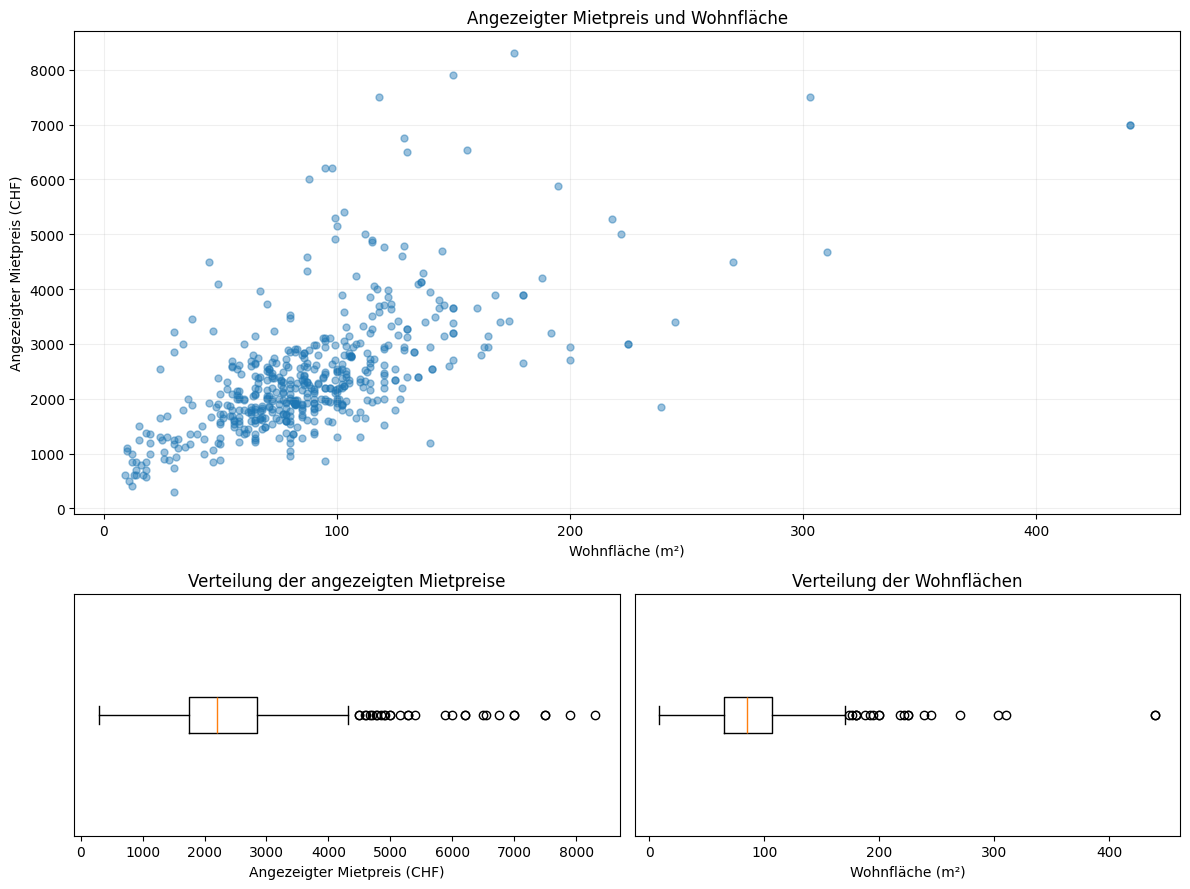

In [4]:
plot_data = df_rentals[["price_display", "surface_living"]]

fig = plt.figure(figsize=(12, 9))
grid = fig.add_gridspec(2, 2, height_ratios=[2, 1])

# 1. Zusammenhang zwischen angezeigtem Preis und Wohnfläche
ax = fig.add_subplot(grid[0, :])

ax.scatter(
    plot_data["surface_living"],
    plot_data["price_display"],
    alpha=0.45,
    s=25,
)

ax.set(
    title="Angezeigter Mietpreis und Wohnfläche",
    xlabel="Wohnfläche (m²)",
    ylabel="Angezeigter Mietpreis (CHF)",
)
ax.grid(alpha=0.2)

# 2. Preisverteilung
ax = fig.add_subplot(grid[1, 0])

ax.boxplot(plot_data["price_display"], vert=False)
ax.set(
    title="Verteilung der angezeigten Mietpreise",
    xlabel="Angezeigter Mietpreis (CHF)",
)
ax.set_yticks([])

# 3. Flächenverteilung
ax = fig.add_subplot(grid[1, 1])

ax.boxplot(plot_data["surface_living"], vert=False)
ax.set(
    title="Verteilung der Wohnflächen",
    xlabel="Wohnfläche (m²)",
)
ax.set_yticks([])

plt.tight_layout()
plt.show()

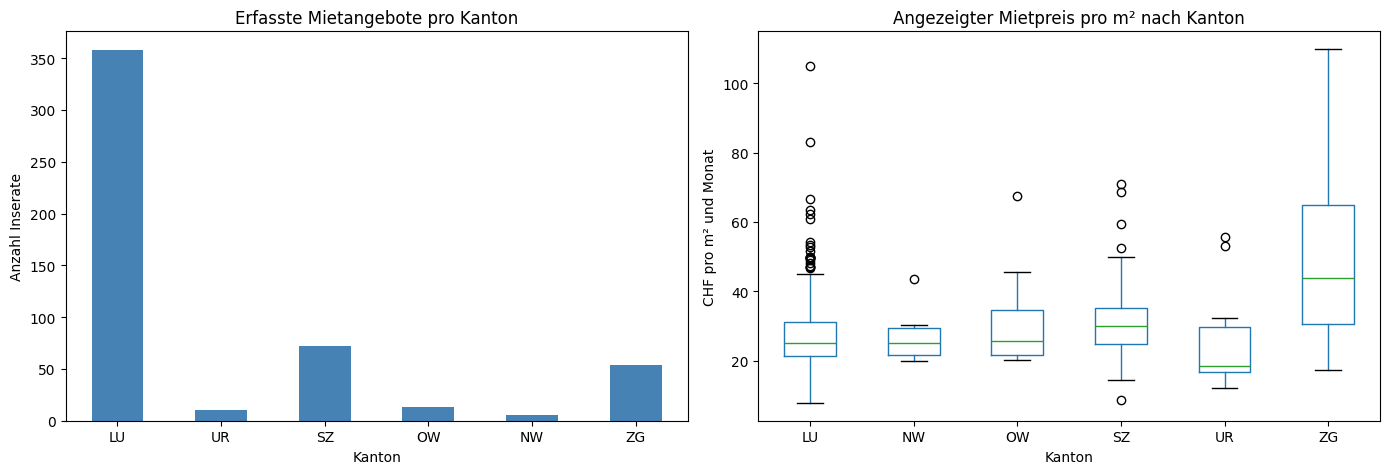

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Anzahl aller erfassten Mietangebote je Kanton.
counts = (
    df_rentals["kanton_geo"]
    .value_counts()
    .reindex(CENTRAL_CANTONS, fill_value=0)
)

counts.plot.bar(ax=axes[0], color="steelblue", rot=0)

axes[0].set(
    title="Erfasste Mietangebote pro Kanton",
    xlabel="Kanton",
    ylabel="Anzahl Inserate",
)

# 2. Angezeigter monatlicher Mietpreis pro m².
df_rentals.boxplot(
    column="price_per_m2",
    by="kanton_geo",
    ax=axes[1],
    grid=False,
)

axes[1].set(
    title="Angezeigter Mietpreis pro m² nach Kanton",
    xlabel="Kanton",
    ylabel="CHF pro m² und Monat",
)

# Automatischen Titel des pandas-Boxplots entfernen.
fig.suptitle("")
plt.tight_layout()
plt.show()

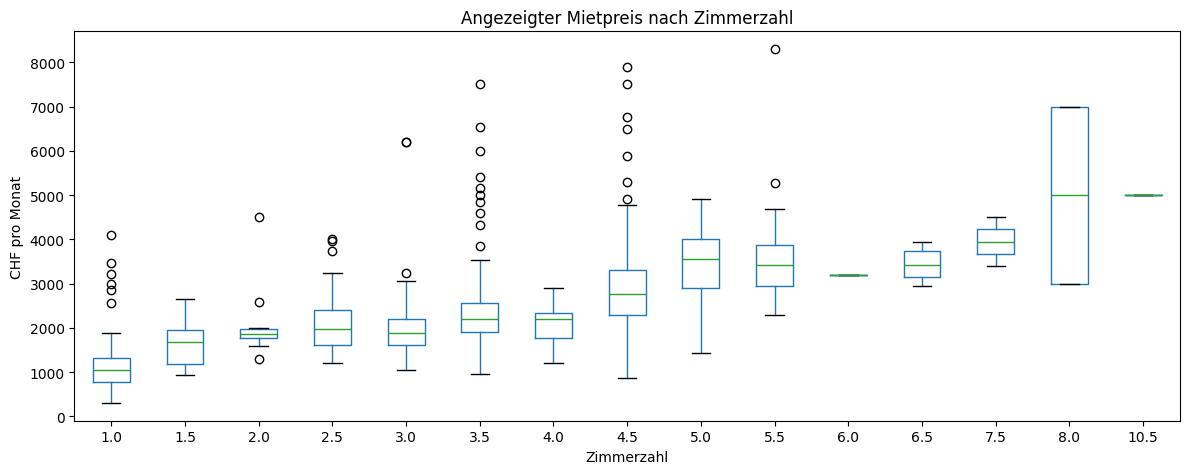

In [6]:
room_data = df_rentals.loc[
    df_rentals["number_of_rooms"].gt(0)
]

fig, ax = plt.subplots(figsize=(12, 5))

room_data.boxplot(
    column="price_display",
    by="number_of_rooms",
    ax=ax,
    grid=False,
)

ax.set(
    title="Angezeigter Mietpreis nach Zimmerzahl",
    xlabel="Zimmerzahl",
    ylabel="CHF pro Monat",
)

fig.suptitle("")
plt.tight_layout()
plt.show()

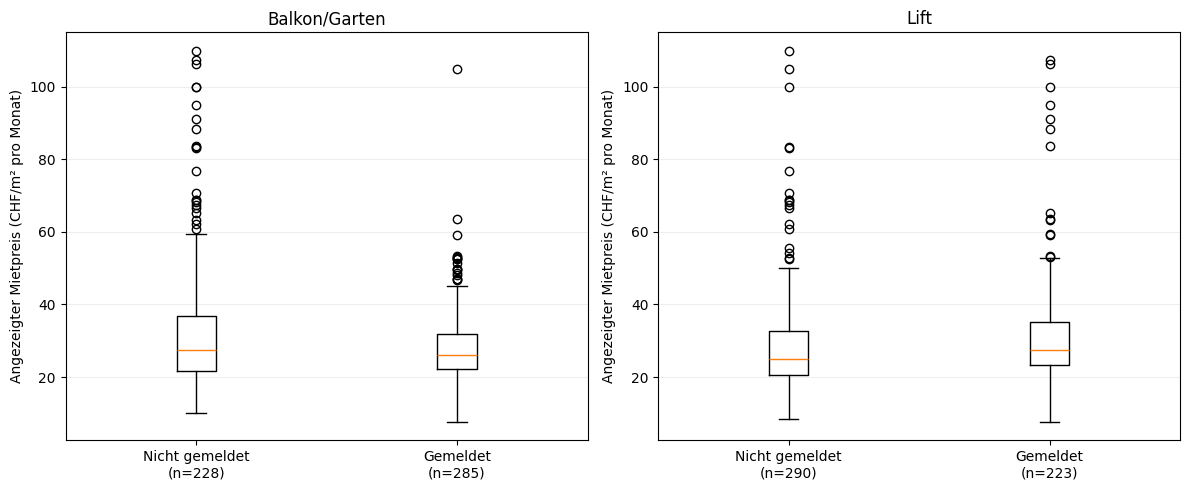

In [7]:
features = [
    ("attribute_reported_balconygarden", "Balkon/Garten"),
    ("attribute_reported_lift", "Lift"),
]
labels = ["Nicht gemeldet", "Gemeldet"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (column, title) in zip(axes, features):
    values = []
    tick_labels = []

    for flag, label in zip([False, True], labels):
        group = df_rentals.loc[
            df_rentals[column].eq(flag), "price_per_m2"
        ].dropna()

        if not group.empty:
            values.append(group)
            tick_labels.append(f"{label}\n(n={len(group)})")

    if values:
        ax.boxplot(values)
        ax.set_xticks(
            range(1, len(tick_labels) + 1),
            labels=tick_labels,
        )
    else:
        ax.text(
            0.5, 0.5, "Keine auswertbaren Angaben",
            ha="center", va="center", transform=ax.transAxes,
        )

    ax.set(
        title=title,
        ylabel="Angezeigter Mietpreis (CHF/m² pro Monat)",
    )
    ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

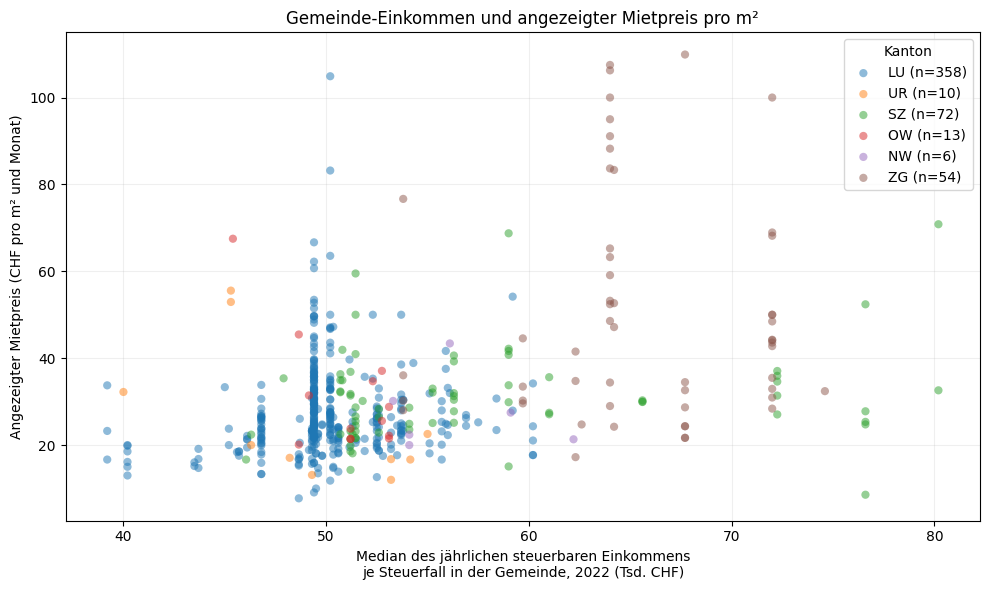

In [8]:
income_data = df_rentals.loc[df_rentals["income_median_chf"].gt(0)]

colors = plt.get_cmap("tab10")

fig, ax = plt.subplots(figsize=(10, 6))

for i, canton in enumerate(CENTRAL_CANTONS):
    subset = income_data.loc[income_data["kanton_geo"].eq(canton)]

    if subset.empty:
        continue

    ax.scatter(
        subset["income_median_chf"] / 1000,
        subset["price_per_m2"],
        label=f"{canton} (n={len(subset)})",
        color=colors(i),
        alpha=0.5,
        s=35,
        edgecolors="none",
    )

ax.set(
    title="Gemeinde-Einkommen und angezeigter Mietpreis pro m²",
    xlabel="Median des jährlichen steuerbaren Einkommens\n"
           "je Steuerfall in der Gemeinde, 2022 (Tsd. CHF)",
    ylabel="Angezeigter Mietpreis (CHF pro m² und Monat)",
)

ax.legend(title="Kanton")
ax.grid(alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

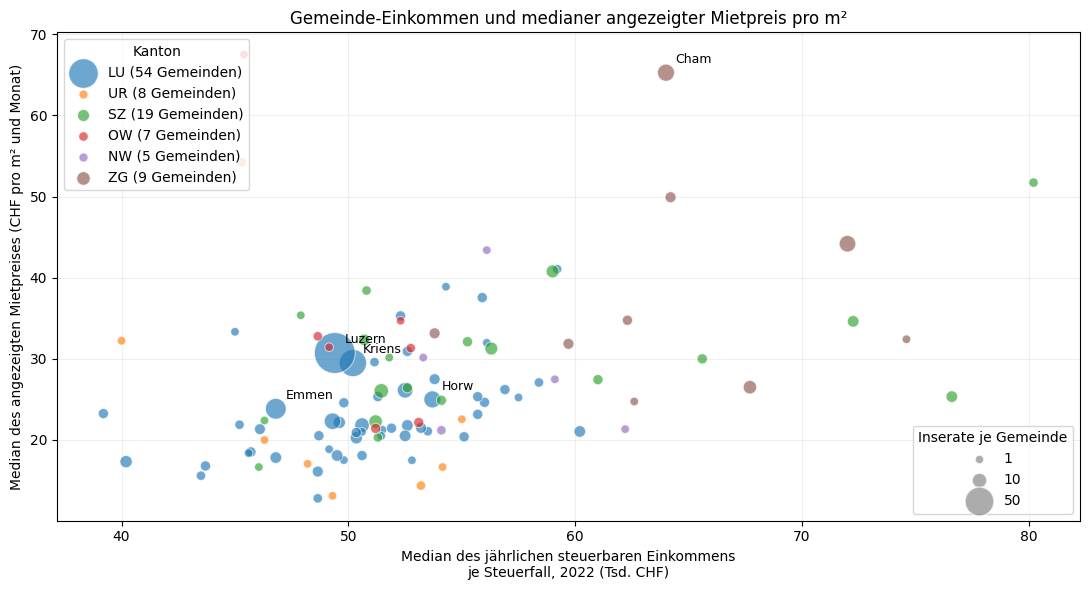

102 Gemeinden mit insgesamt 513 Inseraten


In [9]:
# Pro Gemeinde den Median des angezeigten Mietpreises pro m² berechnen.
gemeinde_data = (
    df_rentals.loc[df_rentals["income_median_chf"].gt(0)]
    .groupby(
        ["gemeinde_bfs", "gemeinde_name", "kanton_geo"],
        as_index=False,
    )
    .agg(
        income_median_chf=("income_median_chf", "first"),
        price_per_m2_median=("price_per_m2", "median"),
        n_listings=("pk", "size"),
    )
)

colors = plt.get_cmap("tab10")

# Punktfläche in pt²: Grundfläche plus Anteil je Inserat.
def point_size(n):
    return 30 + 8 * n


fig, ax = plt.subplots(figsize=(11, 6))

for i, canton in enumerate(CENTRAL_CANTONS):
    subset = gemeinde_data.loc[
        gemeinde_data["kanton_geo"].eq(canton)
    ]

    if subset.empty:
        continue

    ax.scatter(
        subset["income_median_chf"] / 1000,
        subset["price_per_m2_median"],
        s=point_size(subset["n_listings"]),
        color=colors(i),
        alpha=0.65,
        edgecolors="white",
        linewidths=0.7,
        label=f"{canton} ({len(subset)} Gemeinden)",
    )

# Gemeinden mit den meisten Inseraten beschriften.
for _, row in gemeinde_data.nlargest(5, "n_listings").iterrows():
    ax.annotate(
        row["gemeinde_name"],
        (
            row["income_median_chf"] / 1000,
            row["price_per_m2_median"],
        ),
        xytext=(7, 7),
        textcoords="offset points",
        fontsize=9,
    )

# Separate Legenden für Kanton und Punktgrösse.
canton_legend = ax.legend(
    title="Kanton",
    loc="upper left",
)
ax.add_artist(canton_legend)

size_handles = [
    ax.scatter(
        [], [],
        s=point_size(n),
        color="gray",
        alpha=0.65,
        edgecolors="white",
        label=str(n),
    )
    for n in [1, 10, 50]
]

ax.legend(
    handles=size_handles,
    title="Inserate je Gemeinde",
    loc="lower right",
)

ax.set(
    title="Gemeinde-Einkommen und medianer angezeigter Mietpreis pro m²",
    xlabel="Median des jährlichen steuerbaren Einkommens\n"
           "je Steuerfall, 2022 (Tsd. CHF)",
    ylabel="Median des angezeigten Mietpreises (CHF pro m² und Monat)",
)

ax.grid(alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

print(
    f"{len(gemeinde_data)} Gemeinden mit insgesamt "
    f"{gemeinde_data['n_listings'].sum()} Inseraten"
)